In [1]:
import sys
import mlflow
import pandas as pd
import sklearn

print("Python yolu:", sys.executable)
print("MLflow sürümü:", mlflow.__version__)
print("Pandas sürümü:", pd.__version__)
print("Scikit-learn sürümü:", sklearn.__version__)

Python yolu: C:\Users\W-10\anaconda4\envs\akromegali\python.exe
MLflow sürümü: 3.17.2
Pandas sürümü: 3.1.0
Scikit-learn sürümü: 1.9.1


In [2]:
import mlflow

# MLflow sunucusuna bağlan
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Daha önce oluşturduğumuz deneyi seç
experiment = mlflow.set_experiment(
    "Akromegali_Mortalite_Tahmini"
)

print("MLflow bağlantısı başarılı!")
print("Experiment ID:", experiment.experiment_id)
print("Experiment Name:", experiment.name)
print("Tracking URI:", mlflow.get_tracking_uri())

MLflow bağlantısı başarılı!
Experiment ID: 1
Experiment Name: Akromegali_Mortalite_Tahmini
Tracking URI: http://127.0.0.1:5000


In [3]:
import pandas as pd
from pathlib import Path

# Veri setini yükle
file_path = Path("akromegali_alistirma.csv")

df = pd.read_csv(file_path)

# Veri setinin boyutlarını kontrol et
print("Hasta sayısı:", df.shape[0])
print("Değişken sayısı:", df.shape[1])

# İlk 5 satırı görüntüle
display(df.head())

Hasta sayısı: 607
Değişken sayısı: 61


,Alive,Age,Age_in_Diagnosis,Gender,Follow_Up_Duration_Month,Disease_Duration_Month,Preop_Tm_Size_MAX_mm,Kav_INV,Preop_NADIR_GH_OGTT,Preop_GH,...,Mitosis,ki_67,p53,Macro_Micro,Comb_therapy,Last_IGF1,Tiroid_ca,Kolon_ca,MALIGNANCY_OTHER_COMBINED,Pituitary_Adenoma
0,0,85.0,70.0,0,93.0,215.0,5.0,0.0,20.38,0.19,...,NaN,NaN,NaN,0.0,1,524.09,1,0,OTHER,Microadenoma
1,1,70.0,50.0,0,28.0,245.0,10.6,NaN,NaN,NaN,...,0.02,0.0,NaN,1.0,0,NaN,0,0,NO_MALIGNANCY,Macroadenoma
2,1,55.0,40.0,0,134.0,125.0,1.0,0.0,NaN,0.07,...,NaN,NaN,NaN,0.0,0,180.50,0,0,NO_MALIGNANCY,Microadenoma
3,1,65.0,40.0,1,19.0,327.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0,473.34,0,0,NO_MALIGNANCY,NaN
4,1,20.0,20.0,0,51.0,172.0,NaN,NaN,32.75,28.14,...,NaN,NaN,NaN,NaN,0,176.20,0,0,NO_MALIGNANCY,NaN


In [4]:
import hashlib

with open("akromegali_alistirma.csv", "rb") as f:
    dataset_md5 = hashlib.md5(f.read()).hexdigest()

print("Dataset MD5:", dataset_md5)

Dataset MD5: 55e06b11c0d58928075bf955bd76dbaf


In [5]:
from sklearn.model_selection import train_test_split

# Modelde kullanılacak değişkenler
features = [
    "Age_in_Diagnosis",
    "Gender",
    "Preop_GH",
    "Preop_IGF_1",
    "Preop_Tm_Size_MAX_mm"
]

X = df[features]

# Alive = 0 vefat anlamına geliyor.
# Vefat sınıfını pozitif sınıf (1) olarak tanımlıyoruz.
y = (df["Alive"] == 0).astype(int)

# Eğitim ve test ayrımı
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Eğitim verisi:", X_train.shape)
print("Test verisi:", X_test.shape)

print("\nEğitim setinde vefat:", y_train.sum())
print("Test setinde vefat:", y_test.sum())

Eğitim verisi: (485, 5)
Test verisi: (122, 5)

Eğitim setinde vefat: 41
Test setinde vefat: 10


In [6]:
#Neden stratify=y kullandık?
#Çünkü veri setimizde vefat eden hastaların oranı yalnızca %8,4.
#stratify=y, eğitim ve test setlerinde sınıf oranlarının yaklaşık olarak korunmasını sağlıyor.

DummyClassifier Modeli

In [10]:
#Modeli Eğitme

#Veri setimizde çoğunluk sınıfı hayatta olan hastalar olduğu için model bütün hastaları hayatta olarak tahmin edecek.

from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(
    strategy="most_frequent" 
)

# Modeli eğit
dummy_model.fit(X_train, y_train)

# Tahminleri oluştur
y_pred = dummy_model.predict(X_test)

# Vefat sınıfının tahmin olasılıkları
y_proba = dummy_model.predict_proba(X_test)[:, 1]

print("DummyClassifier eğitildi.")

DummyClassifier eğitildi.


In [11]:
#Performans Metriklerini Hesaplama

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_test, y_proba)

pr_auc = average_precision_score(y_test, y_proba)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC (AP):", round(pr_auc, 4))

Accuracy: 0.918
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.5
PR-AUC (AP): 0.082


Accuracy %91,8 olmasına rağmen model vefat eden hiçbir hastayı tespit edemiyor.

In [12]:
import mlflow
import mlflow.sklearn

# MLflow sunucusuna bağlan
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Deneyimizi seç
mlflow.set_experiment(
    "Akromegali_Mortalite_Tahmini"
)

# Yeni deney kaydı oluştur
with mlflow.start_run(run_name="DummyClassifier"):

    # 1. Model parametrelerini kaydet
    mlflow.log_params(dummy_model.get_params())

    # 2. Performans metriklerini kaydet
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision_death", precision)
    mlflow.log_metric("recall_death", recall)
    mlflow.log_metric("f1_death", f1)
    mlflow.log_metric("roc_auc", roc_auc)
    mlflow.log_metric("pr_auc", pr_auc)

    # 3. Kullanılan özellik listesini kaydet
    mlflow.log_dict(
        {"features": features},
        "feature_list.json"
    )

    # 4. Veri dosyasının MD5 değerini kaydet
    mlflow.set_tag("dataset_md5", dataset_md5)

    # 5. Eğitilen modeli kaydet
    mlflow.sklearn.log_model(
        sk_model=dummy_model,
        name="model"
    )

    print("DummyClassifier MLflow'a kaydedildi!")
    print("Run ID:", mlflow.active_run().info.run_id)

DummyClassifier MLflow'a kaydedildi!
Run ID: 6a34f27d15c34e4fa2e68f9ea5c1a2dd
🏃 View run DummyClassifier at: http://127.0.0.1:5000/#/experiments/1/runs/6a34f27d15c34e4fa2e68f9ea5c1a2dd
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Logistic Regression Modeli

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Sayısal değişkenler
numeric_features = [
    "Age_in_Diagnosis",
    "Preop_GH",
    "Preop_IGF_1",
    "Preop_Tm_Size_MAX_mm"
]

# Kategorik değişkenler
categorical_features = ["Gender"]

# Sayısal değişkenlerin hazırlanması
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Kategorik değişkenlerin hazırlanması
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Ön işleme adımlarını birleştirme
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Logistic Regression Pipeline
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Logistic Regression Pipeline oluşturuldu.")

Logistic Regression Pipeline oluşturuldu.


In [16]:
#Modeli eğitelim

# Logistic Regression modelini eğit
logistic_pipeline.fit(X_train, y_train)

# Test verisi üzerinde tahmin yap
y_pred_lr = logistic_pipeline.predict(X_test)

# Vefat sınıfının tahmin olasılıklarını hesapla
y_proba_lr = logistic_pipeline.predict_proba(X_test)[:, 1]

print("Logistic Regression modeli başarıyla eğitildi.")

Logistic Regression modeli başarıyla eğitildi.


In [17]:
#Performans Metrikleri
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Logistic Regression metrikleri
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)

lr_roc_auc = roc_auc_score(y_test, y_proba_lr)
lr_pr_auc = average_precision_score(y_test, y_proba_lr)

print("LOGISTIC REGRESSION SONUÇLARI")
print("----------------------------")
print(f"Accuracy: {lr_accuracy:.4f}")
print(f"Precision (Death): {lr_precision:.4f}")
print(f"Recall (Death): {lr_recall:.4f}")
print(f"F1 (Death): {lr_f1:.4f}")
print(f"ROC-AUC: {lr_roc_auc:.4f}")
print(f"PR-AUC (AP): {lr_pr_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION SONUÇLARI
----------------------------
Accuracy: 0.7049
Precision (Death): 0.1750
Recall (Death): 0.7000
F1 (Death): 0.2800
ROC-AUC: 0.8049
PR-AUC (AP): 0.3710

Confusion Matrix:
[[79 33]
 [ 3  7]]


In [18]:
import mlflow
import mlflow.sklearn

# MLflow bağlantısı
mlflow.set_tracking_uri("http://127.0.0.1:5000")

mlflow.set_experiment("Akromegali_Mortalite_Tahmini")

# Logistic Regression deneyi
with mlflow.start_run(run_name="LogisticRegression") as run:

    # 1. Model parametreleri
    mlflow.log_params({
        "model": "LogisticRegression",
        "max_iter": 1000,
        "class_weight": "balanced",
        "random_state": 42,
        "imputation": "median",
        "scaling": "StandardScaler",
        "encoding": "OneHotEncoder",
        "test_size": 0.20
    })

    # 2. Performans metrikleri
    mlflow.log_metrics({
        "accuracy": lr_accuracy,
        "precision_death": lr_precision,
        "recall_death": lr_recall,
        "f1_death": lr_f1,
        "roc_auc": lr_roc_auc,
        "pr_auc": lr_pr_auc
    })

    # 3. Kullanılan özellikler
    mlflow.log_dict(
        {"features": features},
        "feature_list.json"
    )

    # 4. Veri dosyasının MD5 değeri
    mlflow.set_tag("dataset_md5", dataset_md5)

    # 5. Eğitilen model ve Pipeline
    model_info = mlflow.sklearn.log_model(
        sk_model=logistic_pipeline,
        name="model"
    )

    print("Logistic Regression MLflow'a kaydedildi!")
    print("Run ID:", run.info.run_id)
    print("Model URI:", model_info.model_uri)

🏃 View run LogisticRegression at: http://127.0.0.1:5000/#/experiments/1/runs/0518d2ca71ff45209d34e13de36ecd5b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


MlflowException: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype'].

In [19]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Önceki Logistic Regression kaydımızın ID'si
run_id = "0518d2ca71ff45209d34e13de36ecd5b"

# Mevcut kayda modeli ekle
with mlflow.start_run(run_id=run_id):

    model_info = mlflow.sklearn.log_model(
        sk_model=logistic_pipeline,
        name="model",
        serialization_format="skops",
        skops_trusted_types=["numpy.dtype"]
    )

    print("Logistic Regression modeli kaydedildi!")
    print("Model URI:", model_info.model_uri)

Logistic Regression modeli kaydedildi!
Model URI: models:/m-32a19447b6f34562a0479b0f41e6a2fe
🏃 View run LogisticRegression at: http://127.0.0.1:5000/#/experiments/1/runs/0518d2ca71ff45209d34e13de36ecd5b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Random Forest Modeli

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Random Forest için sayısal değişkenler
numeric_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    ))
])

# Kategorik değişkenler
categorical_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Ön işleme
preprocessor_rf = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_rf, numeric_features),
        ("cat", categorical_transformer_rf, categorical_features)
    ]
)

# Random Forest Pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest Pipeline oluşturuldu.")

Random Forest Pipeline oluşturuldu.


In [26]:
#Modeli Eğitme ve Performansını Ölçme

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Modeli eğit
rf_pipeline.fit(X_train, y_train)

# Test tahminleri
y_pred_rf = rf_pipeline.predict(X_test)

# Vefat olasılıkları
y_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

# Performans metrikleri
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, y_proba_rf)
rf_pr_auc = average_precision_score(y_test, y_proba_rf)

print("RANDOM FOREST SONUÇLARI")
print("-----------------------")
print(f"Accuracy: {rf_accuracy:.4f}")
print(f"Precision (Death): {rf_precision:.4f}")
print(f"Recall (Death): {rf_recall:.4f}")
print(f"F1 (Death): {rf_f1:.4f}")
print(f"ROC-AUC: {rf_roc_auc:.4f}")
print(f"PR-AUC (AP): {rf_pr_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST SONUÇLARI
-----------------------
Accuracy: 0.7541
Precision (Death): 0.1667
Recall (Death): 0.5000
F1 (Death): 0.2500
ROC-AUC: 0.6683
PR-AUC (AP): 0.3687

Confusion Matrix:
[[87 25]
 [ 5  5]]


In [27]:
import mlflow
import mlflow.sklearn

# MLflow bağlantısı
mlflow.set_tracking_uri("http://127.0.0.1:5000")

mlflow.set_experiment("Akromegali_Mortalite_Tahmini")

# Yeni deney oluştur
with mlflow.start_run(run_name="RandomForest") as run:

    # 1. Parametreler
    mlflow.log_params({
        "model": "RandomForestClassifier",
        "n_estimators": 200,
        "max_depth": 5,
        "class_weight": "balanced",
        "random_state": 42,
        "imputation": "median",
        "encoding": "OneHotEncoder",
        "test_size": 0.20
    })

    # 2. Performans metrikleri
    mlflow.log_metrics({
        "accuracy": rf_accuracy,
        "precision_death": rf_precision,
        "recall_death": rf_recall,
        "f1_death": rf_f1,
        "roc_auc": rf_roc_auc,
        "pr_auc": rf_pr_auc
    })

    # 3. Kullanılan özellikler
    mlflow.log_dict(
        {"features": features},
        "feature_list.json"
    )

    # 4. Veri setinin MD5 değeri
    mlflow.set_tag("dataset_md5", dataset_md5)

    # 5. Eğitilmiş modeli ve Pipeline'ı kaydet
    model_info = mlflow.sklearn.log_model(
        sk_model=rf_pipeline,
        name="model",
        serialization_format="skops",
        skops_trusted_types=["numpy.dtype"]
    )

    print("Random Forest MLflow'a kaydedildi!")
    print("Run ID:", run.info.run_id)
    print("Model URI:", model_info.model_uri)

🏃 View run RandomForest at: http://127.0.0.1:5000/#/experiments/1/runs/a177b4195825445697c9ede257c6b489
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


MlflowException: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['sklearn.tree._tree.Tree'].

- sklearn.tree._tree.Tree: sklearn.tree._tree.Tree (the shared node storage for DecisionTree*, RandomForest*, ExtraTrees*, and GradientBoosting* models) stores raw node indices (left_child, right_child, feature) that scikit-learn indexes into without bounds checking. A malicious file can set these to out-of-range values: skops loads the object successfully, but calling .predict() on it can then crash the process (segfault) or read out-of-bounds memory. If you created the file yourself or otherwise fully trust its source, you can load it with trusted=["sklearn.tree._tree.Tree"].

Only add the specific types you have reviewed and trust to the `trusted` argument; avoid passing everything repo

In [28]:
import mlflow
import mlflow.sklearn

# MLflow bağlantısı
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Hata aldığımız Random Forest deneyinin ID'si
run_id = "a177b4195825445697c9ede257c6b489"

# Mevcut deney kaydını yeniden aç
with mlflow.start_run(run_id=run_id):

    model_info = mlflow.sklearn.log_model(
        sk_model=rf_pipeline,
        name="model",
        serialization_format="skops",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.tree._tree.Tree"
        ]
    )

    print("Random Forest modeli başarıyla kaydedildi!")
    print("Run ID:", run_id)
    print("Model URI:", model_info.model_uri)

Random Forest modeli başarıyla kaydedildi!
Run ID: a177b4195825445697c9ede257c6b489
Model URI: models:/m-aaa247258efd4ce5a325094afee144c0
🏃 View run RandomForest at: http://127.0.0.1:5000/#/experiments/1/runs/a177b4195825445697c9ede257c6b489
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [29]:
import pandas as pd

from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_validate
)

# Çapraz doğrulama yöntemi
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

# Modellerimiz
models = {
    "DummyClassifier": dummy_model,
    "LogisticRegression": logistic_pipeline,
    "RandomForest": rf_pipeline
}

# Değerlendirme metrikleri
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision_death": "precision",
    "recall_death": "recall",
    "f1_death": "f1"
}

results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    result = {"Model": model_name}

    for metric in scoring:

        values = scores[f"test_{metric}"]

        result[f"{metric}_mean"] = values.mean()
        result[f"{metric}_std"] = values.std()

    results.append(result)

cv_results = pd.DataFrame(results)

display(cv_results.round(4))

,Model,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,precision_death_mean,precision_death_std,recall_death_mean,recall_death_std,f1_death_mean,f1_death_std
0,DummyClassifier,0.9155,0.0041,0.5000,0.0000,0.0845,0.0041,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,LogisticRegression,0.7464,0.0382,0.8205,0.0717,0.4043,0.1370,0.2092,0.0466,0.7117,0.1703,0.3223,0.0708
2,RandomForest,0.8041,0.0486,0.7574,0.0685,0.3020,0.0925,0.2145,0.0758,0.4483,0.1377,0.2835,0.0848


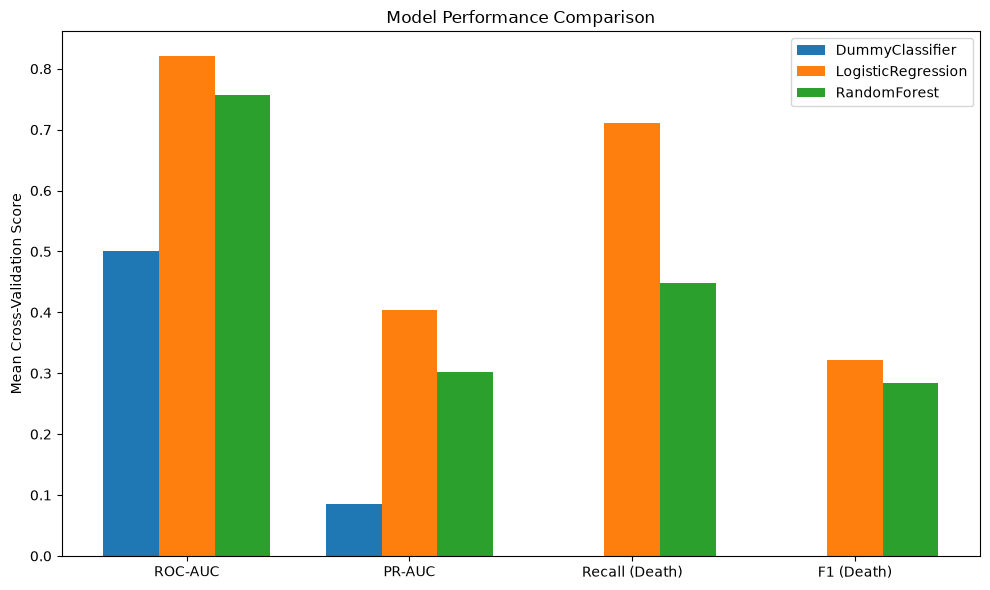

In [30]:
import matplotlib.pyplot as plt

metrics = [
    "roc_auc",
    "pr_auc",
    "recall_death",
    "f1_death"
]

fig, ax = plt.subplots(figsize=(10, 6))

x = range(len(metrics))
width = 0.25

for i, (_, row) in enumerate(cv_results.iterrows()):

    values = [
        row[f"{metric}_mean"]
        for metric in metrics
    ]

    ax.bar(
        [p + i * width for p in x],
        values,
        width=width,
        label=row["Model"]
    )

ax.set_xticks(
    [p + width for p in x]
)

ax.set_xticklabels([
    "ROC-AUC",
    "PR-AUC",
    "Recall (Death)",
    "F1 (Death)"
])

ax.set_ylabel("Mean Cross-Validation Score")
ax.set_title("Model Performance Comparison")
ax.legend()

plt.tight_layout()
plt.savefig("model_comparison_cv.png", dpi=300)
plt.show()

In [31]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")

mlflow.set_experiment(
    "Akromegali_Mortalite_Tahmini"
)

for _, row in cv_results.iterrows():

    model_name = row["Model"]

    with mlflow.start_run(
        run_name=f"{model_name}_RepeatedCV"
    ):

        mlflow.log_params({
            "cv_method": "RepeatedStratifiedKFold",
            "n_splits": 5,
            "n_repeats": 5,
            "random_state": 42
        })

        for metric in scoring:

            mlflow.log_metric(
                f"cv_{metric}_mean",
                float(row[f"{metric}_mean"])
            )

            mlflow.log_metric(
                f"cv_{metric}_std",
                float(row[f"{metric}_std"])
            )

        mlflow.set_tag(
            "dataset_md5",
            dataset_md5
        )

        mlflow.log_dict(
            {"features": features},
            "feature_list.json"
        )

        mlflow.set_tag(
            "evaluation_type",
            "repeated_cross_validation"
        )

print("Cross-validation sonuçları MLflow'a kaydedildi!")

🏃 View run DummyClassifier_RepeatedCV at: http://127.0.0.1:5000/#/experiments/1/runs/7ada6201959f4bff80f8f12eb5f03416
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run LogisticRegression_RepeatedCV at: http://127.0.0.1:5000/#/experiments/1/runs/5082115ab7ef40699510ab313e20d38a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run RandomForest_RepeatedCV at: http://127.0.0.1:5000/#/experiments/1/runs/118495026ae343c8a88b5c5b60834575
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Cross-validation sonuçları MLflow'a kaydedildi!


In [32]:
#FALSE POSITIVE Hastaları Bulma

import pandas as pd

# Test setinin kopyasını oluştur
fp_analysis = X_test.copy()

# Gerçek durum ve tahminleri ekle
fp_analysis["Actual_Death"] = y_test
fp_analysis["Predicted_Death"] = y_pred_lr
fp_analysis["Death_Probability"] = y_proba_lr

# False Positive hastaları filtrele
false_positives = fp_analysis[
    (fp_analysis["Actual_Death"] == 0) &
    (fp_analysis["Predicted_Death"] == 1)
].copy()

# En yüksek ölüm olasılığına göre sırala
false_positives = false_positives.sort_values(
    by="Death_Probability",
    ascending=False
)

print("False Positive hasta sayısı:", len(false_positives))

display(false_positives.head(10))

False Positive hasta sayısı: 33


,Age_in_Diagnosis,Gender,Preop_GH,Preop_IGF_1,Preop_Tm_Size_MAX_mm,Actual_Death,Predicted_Death,Death_Probability
240,65.0,0,0.35,255.9,NaN,0,1,0.977063
70,65.0,1,4.91,350.6,15.3,0,1,0.916168
598,55.0,1,7.00,734.2,NaN,0,1,0.901319
427,50.0,0,2.21,247.0,NaN,0,1,0.898394
358,55.0,1,NaN,312.1,NaN,0,1,0.857941
267,75.0,1,5.10,1049.6,11.6,0,1,0.854428
296,50.0,0,NaN,NaN,37.0,0,1,0.850810
182,60.0,0,1.75,589.6,20.2,0,1,0.808656
446,45.0,0,1.16,443.8,NaN,0,1,0.798603
516,60.0,1,7.90,411.6,9.9,0,1,0.754129


In [33]:
# En yüksek tahmin olasılığına sahip false positive hasta
selected_patient = false_positives.iloc[[0]]

print("Seçilen hastanın veri setindeki satır indeksi:",
      selected_patient.index[0])

print("\nHastanın özellikleri:")

display(selected_patient.T)

Seçilen hastanın veri setindeki satır indeksi: 240

Hastanın özellikleri:


,240
Age_in_Diagnosis,65.000000
Gender,0.000000
Preop_GH,0.350000
Preop_IGF_1,255.900000
Preop_Tm_Size_MAX_mm,NaN
Actual_Death,0.000000
Predicted_Death,1.000000
Death_Probability,0.977063


In [34]:
#Değişken Katkılarını Hesaplama

import numpy as np
import pandas as pd

# Eğitilmiş Pipeline bileşenlerini al
preprocessor_fitted = logistic_pipeline.named_steps["preprocessor"]
classifier_fitted = logistic_pipeline.named_steps["classifier"]

# Ön işlem sonrası değişken isimleri
feature_names = preprocessor_fitted.get_feature_names_out()

# Model katsayıları
coefficients = classifier_fitted.coef_[0]

# Seçilen hastanın yalnızca model özelliklerini al
patient_X = selected_patient[features]

# Hastanın özelliklerini eğitimde öğrenilen işlemlerle dönüştür
patient_transformed = preprocessor_fitted.transform(patient_X)

if hasattr(patient_transformed, "toarray"):
    patient_transformed = patient_transformed.toarray()

patient_values = np.asarray(patient_transformed)[0]

# Her değişkenin log-odds katkısı
contributions = patient_values * coefficients

contribution_df = pd.DataFrame({
    "Feature": feature_names,
    "Transformed_Value": patient_values,
    "Coefficient": coefficients,
    "Contribution": contributions
})

contribution_df["Absolute_Contribution"] = (
    contribution_df["Contribution"].abs()
)

contribution_df = contribution_df.sort_values(
    "Absolute_Contribution",
    ascending=False
)

display(contribution_df.round(4))

,Feature,Transformed_Value,Coefficient,Contribution,Absolute_Contribution
0,num__Age_in_Diagnosis,2.1157,1.2313,2.6050,2.6050
7,num__missingindicator_Preop_Tm_Size_MAX_mm,1.9872,0.6161,1.2244,1.2244
2,num__Preop_IGF_1,-1.2818,-0.6601,0.8461,0.8461
1,num__Preop_GH,-0.9498,-0.7605,0.7223,0.7223
6,num__missingindicator_Preop_IGF_1,-0.7581,0.6224,-0.4718,0.4718
8,cat__Gender_0,1.0000,-0.3230,-0.3230,0.3230
5,num__missingindicator_Preop_GH,-0.6724,-0.4587,0.3084,0.3084
3,num__Preop_Tm_Size_MAX_mm,-0.1970,0.9144,-0.1801,0.1801
4,num__missingindicator_Age_in_Diagnosis,-0.1963,-0.2808,0.0551,0.0551
9,cat__Gender_1,0.0000,0.3203,0.0000,0.0000


In [35]:
#Hasta Tahmini Doğrulama

from scipy.special import expit

intercept = classifier_fitted.intercept_[0]

# Sabit terim + özellik katkıları
log_odds = intercept + contributions.sum()

# Olasılığa dönüştür
calculated_probability = expit(log_odds)

# Modelin kendi tahmini
model_probability = logistic_pipeline.predict_proba(patient_X)[0, 1]

print("Intercept:", round(intercept, 4))
print("Toplam log-odds:", round(log_odds, 4))

print(
    "Katkılardan hesaplanan ölüm olasılığı:",
    round(calculated_probability, 4)
)

print(
    "Modelin tahmin ettiği ölüm olasılığı:",
    round(model_probability, 4)
)

print(
    "Hesaplamalar eşleşiyor mu?",
    np.isclose(calculated_probability, model_probability)
)

Intercept: -1.0347
Toplam log-odds: 3.7518
Katkılardan hesaplanan ölüm olasılığı: 0.9771
Modelin tahmin ettiği ölüm olasılığı: 0.9771
Hesaplamalar eşleşiyor mu? True


Genel Model Yorumlama

,Feature,Coefficient,Abs_Coefficient
0,num__Age_in_Diagnosis,1.2313,1.2313
3,num__Preop_Tm_Size_MAX_mm,0.9144,0.9144
1,num__Preop_GH,-0.7605,0.7605
2,num__Preop_IGF_1,-0.6601,0.6601
6,num__missingindicator_Preop_IGF_1,0.6224,0.6224
7,num__missingindicator_Preop_Tm_Size_MAX_mm,0.6161,0.6161
5,num__missingindicator_Preop_GH,-0.4587,0.4587
8,cat__Gender_0,-0.3230,0.3230
9,cat__Gender_1,0.3203,0.3203
4,num__missingindicator_Age_in_Diagnosis,-0.2808,0.2808


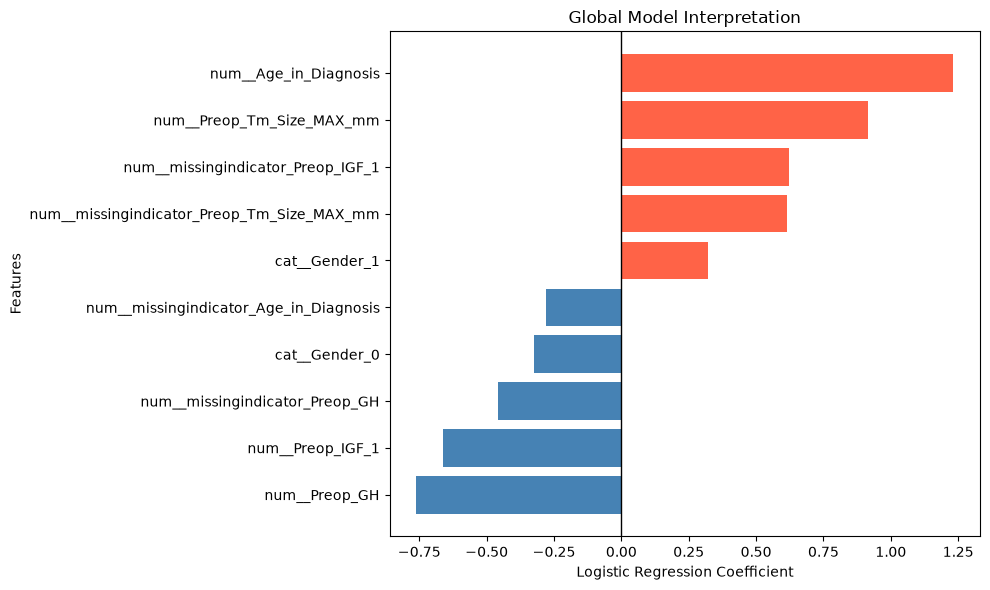

In [36]:
#Görselleştirme

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Eğitilmiş modelin değişken isimleri
feature_names = (
    logistic_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Logistic Regression katsayıları
coefficients = (
    logistic_pipeline
    .named_steps["classifier"]
    .coef_[0]
)

# Katsayı tablosu
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Mutlak katsayı büyüklüğüne göre sırala
coef_df["Abs_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

display(coef_df.round(4))

# Grafik
plot_df = coef_df.sort_values("Coefficient")

plt.figure(figsize=(10, 6))

colors = np.where(
    plot_df["Coefficient"] > 0,
    "tomato",
    "steelblue"
)

plt.barh(
    plot_df["Feature"],
    plot_df["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.title("Global Model Interpretation")

plt.tight_layout()

plt.savefig(
    "global_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
contribution_df.to_csv(
    "patient_240_contributions.csv",
    index=False
)

coef_df.to_csv(
    "logistic_regression_coefficients.csv",
    index=False
)

In [39]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Önceki Logistic Regression Run ID
run_id = "0518d2ca71ff45209d34e13de36ecd5b"

with mlflow.start_run(run_id=run_id):

    mlflow.log_artifact(
        "patient_240_contributions.csv",
        artifact_path="interpretability"
    )

    mlflow.log_artifact(
        "logistic_regression_coefficients.csv",
        artifact_path="interpretability"
    )

    mlflow.log_artifact(
        "global_feature_importance.png",
        artifact_path="interpretability"
    )

print("Model yorumlama sonuçları MLflow'a kaydedildi!")

🏃 View run LogisticRegression at: http://127.0.0.1:5000/#/experiments/1/runs/0518d2ca71ff45209d34e13de36ecd5b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Model yorumlama sonuçları MLflow'a kaydedildi!


In [41]:
%run run_project.py --no-mlflow

Training DummyClassifier... 


C:\Users\W-10\anaconda4\envs\akromegali\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\W-10\anaconda4\envs\akromegali\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\W-10\anaconda4\envs\akromegali\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\User

Training LogisticRegression... 


C:\Users\W-10\anaconda4\envs\akromegali\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\W-10\anaconda4\envs\akromegali\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\W-10\anaconda4\envs\akromegali\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\User

Training RandomForest... 

Repeated CV results:
              Model  accuracy_mean  accuracy_std  roc_auc_mean  roc_auc_std  pr_auc_mean  pr_auc_std  precision_death_mean  precision_death_std  recall_death_mean  recall_death_std  f1_death_mean  f1_death_std
   DummyClassifier         0.9155        0.0041        0.5000       0.0000       0.0845      0.0041                0.0000               0.0000             0.0000            0.0000         0.0000        0.0000
LogisticRegression         0.7464        0.0382        0.8205       0.0717       0.4043      0.1370                0.2092               0.0466             0.7117            0.1703         0.3223        0.0708
      RandomForest         0.8041        0.0486        0.7574       0.0685       0.3020      0.0925                0.2145               0.0758             0.4483            0.1377         0.2835        0.0848

Test results (descriptive; test set was previously inspected):
              Model  accuracy  precision_death  rec

In [42]:
import sklearn
import pandas as pd
import numpy as np
import mlflow

print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("MLflow:", mlflow.__version__)

Scikit-learn: 1.9.1
Pandas: 3.1.0
NumPy: 2.4.6
MLflow: 3.17.2


In [43]:
# İlk oluşturduğumuz Random Forest modelinin parametreleri

rf_params = rf_pipeline.named_steps["classifier"].get_params()

print("Random Forest Parametreleri")
print("--------------------------")

for param in [
    "n_estimators",
    "max_depth",
    "min_samples_split",
    "min_samples_leaf",
    "class_weight",
    "random_state"
]:
    print(f"{param}: {rf_params[param]}")

Random Forest Parametreleri
--------------------------
n_estimators: 200
max_depth: 5
min_samples_split: 2
min_samples_leaf: 1
class_weight: balanced
random_state: 42


In [44]:
# İlk Random Forest modelimizin tahminleri
original_predictions = rf_pipeline.predict(X_test)

# Tekrar çalıştırılabilir scriptteki model
from run_project import models

new_rf = models()["RandomForest"]
new_rf.fit(X_train, y_train)

new_predictions = new_rf.predict(X_test)

# Tahmin karşılaştırması
import numpy as np

print(
    "Farklı tahmin edilen hasta sayısı:",
    np.sum(original_predictions != new_predictions)
)

print(
    "Tahminler tamamen aynı mı?",
    np.array_equal(original_predictions, new_predictions)
)


Farklı tahmin edilen hasta sayısı: 0
Tahminler tamamen aynı mı? True


In [45]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

# İlk model
proba_original = rf_pipeline.predict_proba(X_test)[:, 1]

# Yeniden eğitilen model
proba_new = new_rf.predict_proba(X_test)[:, 1]

print("Olasılıklar eşleşiyor mu?",
      np.allclose(proba_original, proba_new))

print("Maksimum olasılık farkı:",
      np.max(np.abs(proba_original - proba_new)))

print("\nİlk modelin yeniden hesaplanan metrikleri:")
print("Accuracy:", accuracy_score(y_test, original_predictions))
print("Recall:", recall_score(y_test, original_predictions))
print("ROC-AUC:", roc_auc_score(y_test, proba_original))
print("PR-AUC:", average_precision_score(y_test, proba_original))

Olasılıklar eşleşiyor mu? True
Maksimum olasılık farkı: 1.1102230246251565e-16

İlk modelin yeniden hesaplanan metrikleri:
Accuracy: 0.7540983606557377
Recall: 0.5
ROC-AUC: 0.6683035714285714
PR-AUC: 0.3687082190012211
